# 13 · How much exozodiacal dust can Lazuli tolerate before planet detection time doubles?

Warm dust in the target system (exozodi) adds a diffuse background right where we look for planets, and LBTI/HOSTS shows that some nearby Sun-like stars carry tens to hundreds of "zodis". Whether that matters depends on what else dominates the noise budget. Here we sweep the exozodi level in the ESC exposure-time calculator for a Sun-like star at 10 pc and ask at what level the time to S/N = 5 doubles, for three planet contrasts and two raw coronagraph contrasts.

**Instrument / code:** Lazuli ESC (ExtraSolar Coronagraph), `esc_etc.Simulation.from_default(...)`, `sim.update(scene__exozodi__...)`, `sim.get_int_time_for_snr(...)`.

## Prompt to try in Jupyter AI

> Using `esc_etc` (the Lazuli ESC exposure-time calculator), find how the exozodi background is parameterized (read `get_scene` in `esc_etc/scene.py`: `exobg_flux` and the `scene.exozodi` element) and what units it uses.
> Set up `Simulation.from_default(filter="R3", hoststarmag=4.83, hoststar_band="johnson_v", separation=0.4, contrast=1e-8, ppgain=30)` for a Sun twin at 10 pc, with a planet at 0.4 arcsec (4 AU).
> Convert "zodis" to an exozodi surface brightness with 1 zodi = 22 V mag/arcsec² at 1 AU around a solar-luminosity star, falling as r⁻², and apply it with `sim.update(scene__exozodi__mag=..., scene__exozodi__band="johnson_v")`.
> Sweep 0.1–10⁴ zodis and compute `get_int_time_for_snr(5, frame_time=1000 s)` for planet contrasts 3e-9, 1e-8, 3e-8; normalize each curve to the zero-exozodi time.
> Plot time ratio vs zodis (log x), repeat with raw contrast 1e-9, mark where the ratio reaches 2, and print those zodi levels.
> Also check whether the post-processing gain `ppgain` changes the ratio, and explain why from the noise model.

## Setup

In [1]:
import warnings
from pathlib import Path
import numpy as np
import astropy.units as u
from scipy.optimize import brentq
import matplotlib.pyplot as plt
# plt.style.use('gks')

import esc_etc
from esc_etc import Simulation
warnings.filterwarnings('ignore', module='synphot')
THUMB = Path('thumbs/13_exozodi_tolerance.png')
print('esc_etc', esc_etc.__version__)

esc_etc 0.1.0.post34+geb7fb9af9


## 1. How esc-etc parameterizes exozodi

`get_scene(..., exobg_flux=21.0)` makes `scene.exozodi` a solar-like zodi spectrum with surface brightness `hoststarmag + exobg_flux` mag/arcsec² in the ESC band, i.e. a **delta magnitude per arcsec² relative to the host**. It is then counted over the extraction aperture (Ω = π(λ/2D)²) and multiplied by the FPM throughput, and enters the noise model as pure shot noise. Rather than reason in delta-mags, we set the element's absolute surface brightness in $V$ directly.

In [2]:
V_HOST, D_PC, SEP = 4.83, 10.0, 0.4          # Sun twin at 10 pc, planet at 0.4" = 4 AU
FILTER, FRAME, SNR = 'R3', 1000 * u.s, 5
sim = Simulation.from_default(filter=FILTER, hoststarmag=V_HOST, hoststar_band='johnson_v',
                              separation=SEP, contrast=1e-8, ppgain=30)
ex = sim.scene.exozodi
print(f"default exozodi: mag = {ex.mag:.2f} (= host {V_HOST} + exobg_flux 21.0), band = {ex.band} (None = ESC band)")
r = sim.count_rate_components()
print(f"rates at 0.4\" [e-/s]: planet(1e-8) {r.source:.3g}, speckle {r.speckle:.3g}, local zodi {r.zodi:.3g}, exozodi {r.exozodi:.3g}")
print(f"aperture {sim.sensor.aperture_solid_angle:.4f}, FPM throughput {sim.coronagraph.off_axis_throughput():.2f}")

default exozodi: mag = 25.83 (= host 4.83 + exobg_flux 21.0), band = None (None = ESC band)
rates at 0.4" [e-/s]: planet(1e-8) 0.0837 electron / s, speckle 0.0837 electron / s, local zodi 0.00341 electron / s, exozodi 9.54e-05 electron / s
aperture 0.0016 arcsec2, FPM throughput 0.57


## 2. Zodis → surface brightness

Convention (as in EXOSIMS and Stark et al. 2014): **1 zodi = 22 V mag arcsec⁻² at 1 AU from a solar-luminosity star**, scaling as $r^{-2}$, face-on, no inclination factor. At projected separation $r = \theta\,d$:

$$\mu_V(n) = 22 - 2.5\log_{10} n + 5\log_{10}(r/\mathrm{AU}).$$

In [3]:
r_AU = SEP * D_PC
def sb_zodis(n):
    return 22.0 - 2.5 * np.log10(n) + 5 * np.log10(r_AU)

def n_of_sb(mu):
    return 10 ** (-0.4 * (mu - sb_zodis(1.0)))

print(f"r = {r_AU:.1f} AU -> 1 zodi = {sb_zodis(1):.2f} V mag/arcsec^2  (local zodi default: 22.5)")
for lbl, dm in [('esc-etc from_default (exobg_flux=21)', 21.0), ('config_um_esc value (delta_magnitude=22, Stark+16)', 22.0)]:
    print(f"{lbl}: {V_HOST + dm:.2f} mag/arcsec^2 ~ {n_of_sb(V_HOST + dm):.2f} zodi here (ignoring the V vs ESC-band color)")

r = 4.0 AU -> 1 zodi = 25.01 V mag/arcsec^2  (local zodi default: 22.5)
esc-etc from_default (exobg_flux=21): 25.83 mag/arcsec^2 ~ 0.47 zodi here (ignoring the V vs ESC-band color)
config_um_esc value (delta_magnitude=22, Stark+16): 26.83 mag/arcsec^2 ~ 0.19 zodi here (ignoring the V vs ESC-band color)


## 3. Sweep the exozodi level

`time_to_snr5` sets the exozodi surface brightness in $V$, solves for the integration time (1000 s frames, shortened to half the saturation time for the dustiest cases; closed-form `int_time_continuous`), and resets. The reference case is "no exozodi" (a 99 mag/arcsec² surface brightness).

In [4]:
def time_to_snr5(n_zodi, contrast, raw, ppgain=30):
    mu = 99.0 if n_zodi == 0 else sb_zodis(n_zodi)
    sim.update(scene__exozodi__mag=mu, scene__exozodi__band='johnson_v',
               scene__planet__deltamag=-2.5 * np.log10(contrast),
               coronagraph__raw_dh_contrast=raw, coronagraph__ppgain=ppgain)
    frame = min(FRAME, 0.5 * sim.saturation_time())   # very dusty cases saturate a 1000 s frame
    t = sim.get_int_time_for_snr(SNR, frame)['int_time_continuous'][0].to_value(u.hr)
    sim.reset()
    return t

ZODIS = np.geomspace(0.1, 1e4, 41)
PLANETS = [3e-9, 1e-8, 3e-8]
RAWS = [1e-8, 1e-9]
t0, ratio, n2 = {}, {}, {}
for raw in RAWS:
    for c in PLANETS:
        t0[raw, c] = time_to_snr5(0, c, raw)
        ratio[raw, c] = np.array([time_to_snr5(n, c, raw) for n in ZODIS]) / t0[raw, c]
        n2[raw, c] = 10 ** brentq(lambda lg: time_to_snr5(10 ** lg, c, raw) / t0[raw, c] - 2, -3, 6, xtol=1e-4)
        print(f"raw {raw:.0e}  planet {c:.0e}: t(0 zodi) = {t0[raw, c]:7.2f} h, "
              f"t(1 zodi)/t0 = {np.interp(1, ZODIS, ratio[raw, c]):.3f}, t(10)/t0 = {np.interp(10, ZODIS, ratio[raw, c]):.2f}, "
              f"doubles at {n2[raw, c]:6.0f} zodi")

raw 1e-08  planet 3e-09: t(0 zodi) =    3.84 h, t(1 zodi)/t0 = 1.001, t(10)/t0 = 1.01, doubles at    714 zodi


raw 1e-08  planet 1e-08: t(0 zodi) =    0.31 h, t(1 zodi)/t0 = 1.001, t(10)/t0 = 1.01, doubles at    888 zodi


raw 1e-08  planet 3e-08: t(0 zodi) =    0.05 h, t(1 zodi)/t0 = 1.001, t(10)/t0 = 1.01, doubles at   1384 zodi


raw 1e-09  planet 3e-09: t(0 zodi) =    1.83 h, t(1 zodi)/t0 = 1.002, t(10)/t0 = 1.02, doubles at    491 zodi


raw 1e-09  planet 1e-08: t(0 zodi) =    0.22 h, t(1 zodi)/t0 = 1.002, t(10)/t0 = 1.02, doubles at    665 zodi


raw 1e-09  planet 3e-08: t(0 zodi) =    0.04 h, t(1 zodi)/t0 = 1.001, t(10)/t0 = 1.01, doubles at   1161 zodi


## 4. Does post-processing gain change the tolerance?

In `int_time_for_snr` the time is $t = (R_p + R_\mathrm{bkg}) / \big[(R_p/\mathrm{SNR})^2 - M^2\big]$ with $M = R_\mathrm{speckle}/\mathrm{ppgain}$. Exozodi only adds to $R_\mathrm{bkg}$ in the numerator, so the *ratio* $t(n)/t(0)$ should not depend on `ppgain` at all, even though the absolute time does. Check it:

In [5]:
c = 1e-8
for g in (10, 30, 100):
    r = np.array([time_to_snr5(n, c, 1e-8, ppgain=g) for n in ZODIS]) / time_to_snr5(0, c, 1e-8, ppgain=g)
    print(f"ppgain {g:3d}: t0 = {time_to_snr5(0, c, 1e-8, ppgain=g):6.2f} h, "
          f"max |ratio - ratio(ppgain=30)| = {np.max(np.abs(r - ratio[1e-8, c])):.1e}")
# break-even: doubling happens when the exozodi rate equals planet + all other background rates
sim.update(scene__exozodi__mag=sb_zodis(n2[1e-8, c]), scene__exozodi__band='johnson_v', scene__planet__deltamag=20.0)
rr = sim.count_rate_components(); s = sim.sensor
other = rr.source + rr.speckle + rr.zodi + (s.dark_current * s.num_psf_pixels).to(u.electron / u.s) \
        + (s.read_noise ** 2 * s.num_psf_pixels / FRAME).to(u.electron / u.s)
print(f"at the doubling point: exozodi rate {rr.exozodi:.3g} vs planet + other background {other:.3g}")
sim.reset()

ppgain  10: t0 =   0.40 h, max |ratio - ratio(ppgain=30)| = 1.8e-15


ppgain  30: t0 =   0.31 h, max |ratio - ratio(ppgain=30)| = 0.0e+00


ppgain 100: t0 =   0.30 h, max |ratio - ratio(ppgain=30)| = 1.8e-15
at the doubling point: exozodi rate 0.3 electron / s vs planet + other background 0.3 electron / s


## Hero figure

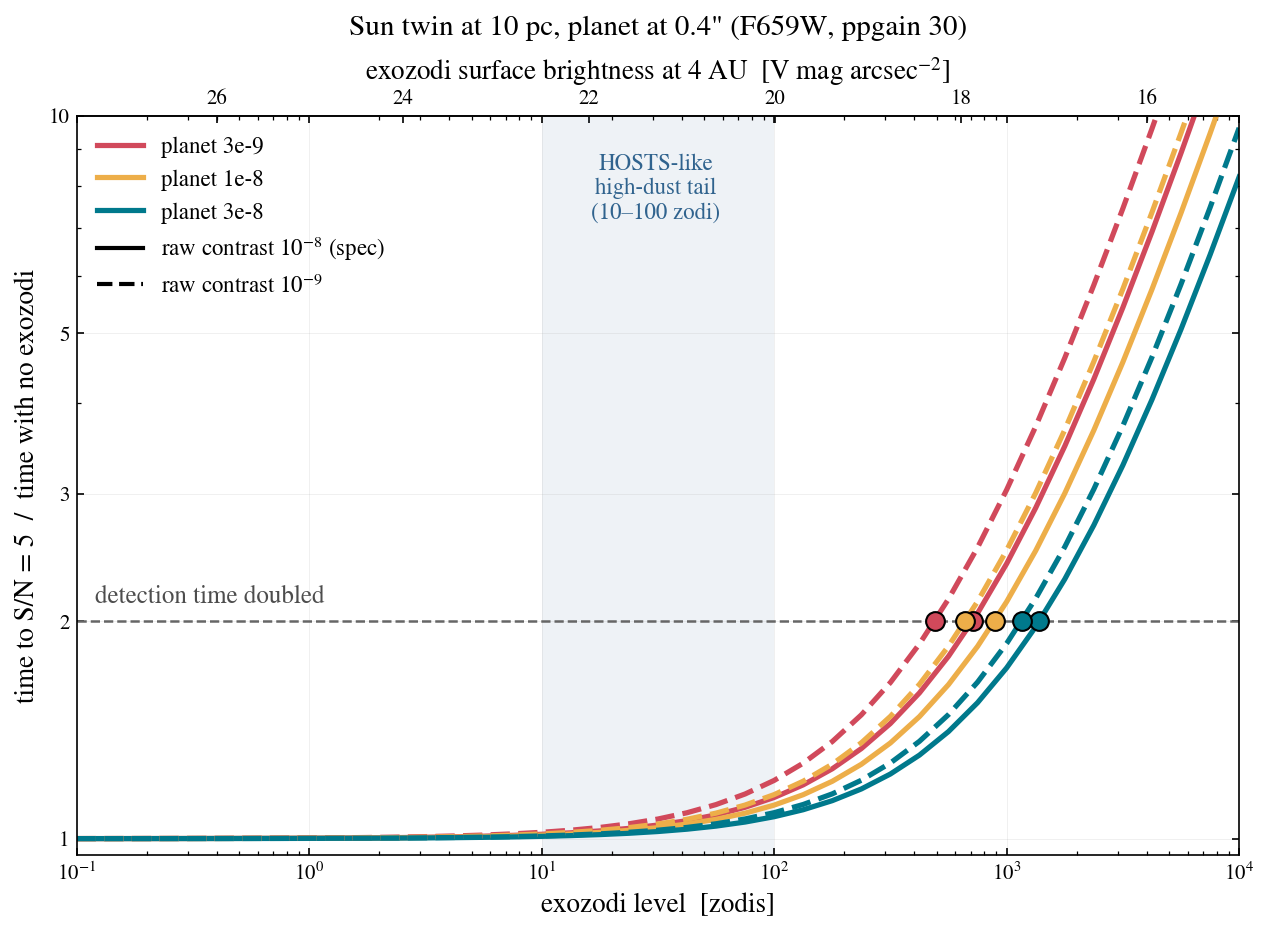

In [6]:
COL = {3e-9: '#d1495b', 1e-8: '#edae49', 3e-8: '#00798c'}
fig, ax = plt.subplots(figsize=(10, 6.4))
for raw, ls in [(1e-8, '-'), (1e-9, '--')]:
    for c in PLANETS:
        lbl = f'planet {c:.0e}'.replace('e-0', 'e-') if raw == 1e-8 else None
        ax.plot(ZODIS, ratio[raw, c], color=COL[c], ls=ls, lw=2.5, label=lbl)
        ax.plot(n2[raw, c], 2, 'o', color=COL[c], ms=9, mec='k', zorder=5)
ax.axhline(2, color='0.4', ls='--', lw=1.2)
ax.text(0.12, 2.12, 'detection time doubled', fontsize=12, color='0.3')
ax.axvspan(10, 100, color='#30638e', alpha=0.08, lw=0)
ax.text(31, 7.2, 'HOSTS-like\nhigh-dust tail\n(10–100 zodi)', ha='center', fontsize=11, color='#30638e')
ax.plot([], [], color='k', ls='-', label='raw contrast $10^{-8}$ (spec)')
ax.plot([], [], color='k', ls='--', label='raw contrast $10^{-9}$')
ax.set(xscale='log', yscale='log', xlim=(0.1, 1e4), ylim=(0.95, 10),
       xlabel='exozodi level  [zodis]', ylabel='time to S/N = 5  /  time with no exozodi')
ax.set_yticks([1, 2, 3, 5, 10]); ax.set_yticklabels(['1', '2', '3', '5', '10'])
top = ax.secondary_xaxis('top', functions=(sb_zodis, n_of_sb))
top.set_xticks([26, 24, 22, 20, 18, 16]); top.xaxis.set_major_formatter('{x:.0f}')
top.set_xlabel(f'exozodi surface brightness at {r_AU:.0f} AU  [V mag arcsec$^{{-2}}$]')
ax.set_title(f'Sun twin at {D_PC:.0f} pc, planet at {SEP}" (F659W, ppgain 30)', fontsize=14, pad=10)
ax.legend(loc='upper left', fontsize=11)
fig.savefig(THUMB, dpi=150)
plt.show()

## Answer

For a Sun twin at 10 pc with the planet at 0.4″ (4 AU), the time to S/N = 5 doubles only at **≈700–1400 zodis** at the spec raw contrast of $10^{-8}$ (714, 888 and 1384 zodis for planet contrasts $3	imes10^{-9}$, $10^{-8}$, $3	imes10^{-8}$), and at ≈500–1200 zodis if the raw contrast were $10^{-9}$; a 10-zodi disk costs only 1–2%. Doubling happens where the exozodi count rate equals the planet plus all other noise rates, so fainter planets and darker dark holes are less tolerant, while `ppgain` changes the absolute time (0.40 → 0.30 h for the $10^{-8}$ planet from ppgain 10 → 100) but leaves the ratio unchanged to machine precision.

## Caveats & next steps

- **Model limits (from the esc-etc docs):** exozodi is a smooth, uniform surface brightness that only adds shot noise; real disks have clumps, rings and inclination-dependent brightness that leave *systematic* residuals after PSF subtraction (not modeled, and `ppgain` only acts on stellar speckle). FPM throughput is applied as a flat scalar to the diffuse terms too; raw contrast is one number independent of separation; planet, host and dust are given flat or solar shapes normalized in $V$ (the V vs F659W color term is ignored).
- **Convention matters:** "1 zodi" here is 22 V mag/arcsec² at 1 AU with $r^{-2}$ falloff and no luminosity or inclination factor; HOSTS defines zodis by the 1 AU-equivalent surface density at the habitable zone, so conversions between papers can differ by factors of a few.
- **Extend it:** (1) repeat at the habitable-zone separation of the nearest Sun-like stars (τ Ceti, ε Eri, 82 Eri) where the $r^{-2}$ falloff makes exozodi much brighter per zodi; (2) add a systematic exozodi residual term (a fraction of the exozodi rate, like `ppgain` for speckles) to the noise model and see how fast the tolerance collapses; (3) switch on RDI (`coronagraph__subtraction='rdi'`), where the reference star's own zodi/exozodi noise is added.